# 01. Data Audit & Initial Cleaning
## Case Study 2: Customer Lifetime Value (CLV) Predictive Analytics

**Business Context & Audit Objective:**
The existing enterprise CLV portal values every customer storage array using a flat **5.0% yearly churn assumption**. In this notebook, we perform an honest, rigorous data audit to answer fundamental analytical questions:
1. What is the actual schema, row count, and entity structure of the dataset?
2. Are there missing values or injected data anomalies (e.g. utilization > 100%, negative profits)?
3. Does the observed 12-month churn rate in the labelled sample match or deviate from the static 5% assumption?
4. What leakage-safe cleaning rules must be established before any feature engineering or modeling?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Plot styling for clear business presentation
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["font.size"] = 11

print("Environment initialized.")

Environment initialized.


### 1. Load Raw Dataset
We load the raw CSV directly from `../data/raw/` without making any modifications to the source file.

In [2]:
# Path resolution robust to running from notebooks/ or project root
raw_path = Path("../data/raw/Case_Study_2_CLV_Predictive_Analytics.csv")
if not raw_path.exists():
    raw_path = Path("data/raw/Case_Study_2_CLV_Predictive_Analytics.csv")

df = pd.read_csv(raw_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(10)

Dataset Dimensions: 2000 rows, 9 columns


,account_id,array_id,contract_end_date,historical_15yr_net_profit_usd,current_capacity_tb,utilization_rate_pct,static_baseline_churn_rate,churn_event_next_12m,expansion_potential_signal
0,ACC_1000,ARR_5000,2026-10-01,146797,1382,0.59,0.05,0.0,Medium
1,ACC_1001,ARR_5001,2026-10-01,1236408,1809,0.93,0.05,1.0,UNKNOWN
2,ACC_1002,ARR_5002,2026-10-02,2790632,605,1.28,0.05,0.0,Low
3,ACC_1003,ARR_5003,2026-10-02,1233288,1567,0.47,0.05,0.0,Low
4,ACC_1004,ARR_5004,2026-10-03,2881167,488,1.22,0.05,0.0,Low
5,ACC_1005,ARR_5005,2026-10-03,2989675,408,0.55,0.05,0.0,Medium
6,ACC_1006,ARR_5006,2026-10-04,2407913,1107,1.24,0.05,0.0,High
7,ACC_1007,ARR_5007,2026-10-04,4046181,1161,1.02,0.05,0.0,Medium
8,ACC_1008,ARR_5008,2026-10-05,-5551,2113,0.56,0.05,0.0,Low
9,ACC_1009,ARR_5009,2026-10-05,3224922,470,0.87,0.05,0.0,Medium


*Initial Inspection*:
The dataset contains 2,000 rows and 9 columns. The fields capture customer accounts, array identifiers, lease expiration dates, 15-year profit, provisioned capacity, utilization, static baseline churn, 12-month churn outcomes, and expansion potential signals.

### 2. Schema and Data Types Audit
Let's check the physical data types and inspect for null values across the columns.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   account_id                      2000 non-null   str    
 1   array_id                        2000 non-null   str    
 2   contract_end_date               2000 non-null   str    
 3   historical_15yr_net_profit_usd  2000 non-null   int64  
 4   current_capacity_tb             2000 non-null   int64  
 5   utilization_rate_pct            2000 non-null   float64
 6   static_baseline_churn_rate      2000 non-null   float64
 7   churn_event_next_12m            1884 non-null   float64
 8   expansion_potential_signal      2000 non-null   str    
dtypes: float64(3), int64(2), str(4)
memory usage: 200.1 KB


*Observation*:
All columns except `churn_event_next_12m` have 2,000 non-null values. `churn_event_next_12m` is stored as float64 and contains missing entries. Let's quantify exact missingness.

### 3. Missing Values Analysis
Which columns contain missing data, and what is the exact missing percentage?

In [ ]:
missing_df = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Missing Count': df.isnull().sum(),
    'Missing Pct (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Complete Rows': df.notnull().sum()
})
missing_df

,Data Type,Missing Count,Missing Pct (%),Complete Rows
account_id,str,0,0.0,2000
array_id,str,0,0.0,2000
contract_end_date,str,0,0.0,2000
historical_15yr_net_profit_usd,int64,0,0.0,2000
current_capacity_tb,int64,0,0.0,2000
utilization_rate_pct,float64,0,0.0,2000
static_baseline_churn_rate,float64,0,0.0,2000
churn_event_next_12m,float64,116,5.8,1884
expansion_potential_signal,str,0,0.0,2000


*Critical Data Quality Rule*:
Exactly 116 rows (5.80%) have missing churn labels in `churn_event_next_12m`. 
**Non-negotiable rule**: We must NEVER impute missing churn labels to 0 ('stayed'). Missing labels reflect unobserved outcomes. We will create an explicit indicator `is_label_known` (1 for labelled, 0 for unlabelled), train only on labelled rows, and score all 2,000 rows during inference.

### 4. Duplicate Checks
Are there any duplicate rows, duplicated array IDs, or repeated account-array pairs in the dataset?

In [5]:
print(f"Full duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate array_id entries: {df['array_id'].duplicated().sum()}")
print(f"Duplicate (account_id, array_id) pairs: {df.duplicated(subset=['account_id', 'array_id']).sum()}")

Full duplicate rows: 0
Duplicate array_id entries: 0
Duplicate (account_id, array_id) pairs: 0


*Observation*:
Zero duplicates exist. Every row uniquely identifies a single physical storage array with IDs ranging from `ARR_5000` to `ARR_6999`.

### 5. Customer Account & Storage Array Hierarchy
How many customer accounts exist, and how many storage arrays does each customer own?

In [6]:
unique_accounts = df['account_id'].nunique()
unique_arrays = df['array_id'].nunique()
arrays_per_account = df['account_id'].value_counts()

print(f"Unique Customer Accounts: {unique_accounts}")
print(f"Unique Storage Arrays: {unique_arrays}")
print("Distribution of Arrays per Account:")
print(arrays_per_account.value_counts())

Unique Customer Accounts: 1000
Unique Storage Arrays: 2000
Distribution of Arrays per Account:
count
2    1000
Name: count, dtype: int64


*Key Architectural Finding*:
There are exactly 1,000 unique customer accounts, and **every account owns exactly 2 storage arrays** (1,000 × 2 = 2,000 arrays).
*Consequence for Validation*: Because the two arrays belonging to a single account share an IT environment and renewal decision-makers, a standard random split would cause severe data leakage across folds. We **must use grouped cross-validation** (`GroupKFold` on `account_id`) to ensure both arrays of any given customer remain together in either train or test.

### 6. Target Variable Audit: Observed 12-Month Churn vs. Static 5% Baseline
What is the actual observed churn rate among labelled arrays, and how does it compare against the portal's static 5.0% baseline assumption?

In [7]:
labelled = df[df['churn_event_next_12m'].notnull()]
n_labelled = len(labelled)
n_churned = int((labelled['churn_event_next_12m'] == 1.0).sum())
n_stayed = int((labelled['churn_event_next_12m'] == 0.0).sum())
obs_churn_rate = n_churned / n_labelled
baseline_rate = 0.05
baseline_bias = obs_churn_rate - baseline_rate

print(f"Labelled sample size: {n_labelled} arrays")
print(f"Observed Churned (1.0): {n_churned} ({obs_churn_rate*100:.2f}%)")
print(f"Observed Stayed (0.0): {n_stayed} ({n_stayed/n_labelled*100:.2f}%)")
print(f"Portal Static Baseline Churn: {baseline_rate*100:.1f}%")
print(f"Expected Churn at 5%: {n_labelled * baseline_rate:.1f} arrays")
print(f"Actual Churn: {n_churned} arrays")
print(f"Overall Baseline Bias: +{baseline_bias*100:.2f}% (Observed churn is {obs_churn_rate/baseline_rate:.2f}x higher)")

# Mathematical bounds across all 2,000 arrays
min_bound = (n_churned / len(df)) * 100
max_bound = ((n_churned + 116) / len(df)) * 100
print(f"Overall Churn Population Bounds: [{min_bound:.2f}%, {max_bound:.2f}%]")

Labelled sample size: 1884 arrays
Observed Churned (1.0): 298 (15.82%)
Observed Stayed (0.0): 1586 (84.18%)
Portal Static Baseline Churn: 5.0%
Expected Churn at 5%: 94.2 arrays
Actual Churn: 298 arrays
Overall Baseline Bias: +10.82% (Observed churn is 3.16x higher)
Overall Churn Population Bounds: [14.90%, 20.70%]


*Empirical Finding*:
In the labelled data, **298 out of 1,884 arrays (15.82%) churned within 12 months**. At 5%, we would expect only ~94 churn events. 
Furthermore, even if every single one of the 116 unlabelled arrays remained retained, the churn rate across the entire fleet would still be **14.90%** (and **20.70%** if all churned). Both bounds prove that actual enterprise churn is more than 3 times higher than the static 5% business assumption.

### 7. Storage Utilization Rate Audit
Is utilization stored as a percentage (0–100) or proportion (0–1)? Are there out-of-bounds values exceeding 100%?

In [8]:
util_stats = df['utilization_rate_pct'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
print(util_stats)

over_capacity_count = (df['utilization_rate_pct'] > 1.0).sum()
over_capacity_pct = (over_capacity_count / len(df)) * 100
print()
print(f"Over-capacity arrays (> 1.0 / > 100%): {over_capacity_count} ({over_capacity_pct:.2f}%)")
print(f"Maximum utilization: {df['utilization_rate_pct'].max():.2f} (145%)")

count    2000.000000
mean        0.917040
std         0.312321
min         0.350000
5%          0.420000
25%         0.660000
50%         0.930000
75%         1.180000
90%         1.340000
95%         1.400000
99%         1.440000
max         1.450000
Name: utilization_rate_pct, dtype: float64

Over-capacity arrays (> 1.0 / > 100%): 862 (43.10%)
Maximum utilization: 1.45 (145%)


*Observation & Domain Interpretation*:
Utilization is formatted as a proportion (range: 0.35 to 1.45). Exactly **862 arrays (43.10%)** exceed 1.0 (100%), with a peak at 1.45.
In enterprise enterprise storage, committed capacity frequently exceeds physical usable space due to thin-provisioning, deduplication, and compression.
*Decision*: We will **NOT delete** these rows. Instead, we engineer:
- `utilization_capped = min(utilization, 1.0)`
- `over_capacity = 1 if utilization > 1.0 else 0`
- `utilization_excess = max(utilization - 1.0, 0.0)`

In [9]:
# Compare churn behavior: Over-capacity vs. Nominal-capacity
lab_over = labelled[labelled['utilization_rate_pct'] > 1.0]
lab_under = labelled[labelled['utilization_rate_pct'] <= 1.0]

print(f"Churn rate in Over-Capacity arrays (>100%): {lab_over['churn_event_next_12m'].mean()*100:.2f}% (N={len(lab_over)})")
print(f"Churn rate in Nominal arrays (<=100%): {lab_under['churn_event_next_12m'].mean()*100:.2f}% (N={len(lab_under)})")

Churn rate in Over-Capacity arrays (>100%): 14.29% (N=812)
Churn rate in Nominal arrays (<=100%): 16.98% (N=1072)


*Observation*:
Arrays exceeding 100% utilization exhibit a slightly lower churn rate (14.29%) than nominal arrays (16.98%), indicating high operational stickiness and higher switching friction for fully saturated environments.

### 8. Profit Audit: Negative Profit Anomaly
What does `historical_15yr_net_profit_usd` look like, and are there negative values?

In [10]:
profit_stats = df['historical_15yr_net_profit_usd'].describe()
print(profit_stats)

neg_profit_count = (df['historical_15yr_net_profit_usd'] < 0).sum()
neg_profit_pct = (neg_profit_count / len(df)) * 100
print()
print(f"Negative-profit arrays: {neg_profit_count} ({neg_profit_pct:.2f}%)")
print(f"Lowest profit observed: ${df['historical_15yr_net_profit_usd'].min():,} USD")
print(f"Highest profit observed: ${df['historical_15yr_net_profit_usd'].max():,} USD")

count    2.000000e+03
mean     2.152845e+06
std      1.330932e+06
min     -9.378000e+04
25%      9.966938e+05
50%      2.134328e+06
75%      3.277240e+06
max      4.498824e+06
Name: historical_15yr_net_profit_usd, dtype: float64

Negative-profit arrays: 58 (2.90%)
Lowest profit observed: $-93,780 USD
Highest profit observed: $4,498,824 USD


*Observation & Handling Rule*:
Profits average \$2.15M, but **58 arrays (2.90%)** have negative profits down to -\$93,780.
*Decision*:
1. Do NOT drop negative-profit arrays.
2. For modeling, compute `profit_signed_log = sign(profit) * log(1 + |profit|)` and `negative_profit_flag`.
3. For financial calculations, preserve exact dollars.
4. Separate negative-profit arrays in reporting so losses are never distorted into artificial positive value exposure.

### 9. Usable Capacity Audit
Does `current_capacity_tb` have invalid non-positive or zero values?

In [11]:
cap_stats = df['current_capacity_tb'].describe()
print(cap_stats)
print(f"Capacity <= 0 TB check: {(df['current_capacity_tb'] <= 0).sum()} anomalies found")

count    2000.000000
mean     1282.771000
std       699.754635
min        53.000000
25%       673.500000
50%      1305.500000
75%      1880.000000
max      2498.000000
Name: current_capacity_tb, dtype: float64
Capacity <= 0 TB check: 0 anomalies found


*Observation*:
Provisioned capacity spans 53 TB to 2,498 TB (mean 1,283 TB) with zero non-positive values. Hardware metrics are well-bounded.

### 10. Expansion Potential Signal Audit
What categories exist in `expansion_potential_signal`, and what is the distribution?

In [12]:
exp_counts = df['expansion_potential_signal'].value_counts()
exp_df = pd.DataFrame({
    'Array Count': exp_counts,
    'Percentage (%)': (exp_counts / len(df) * 100).round(2),
    'Labelled Churn Rate (%)': labelled.groupby('expansion_potential_signal')['churn_event_next_12m'].mean() * 100
})
exp_df

,Array Count,Percentage (%),Labelled Churn Rate (%)
expansion_potential_signal,,,
High,426,21.30,14.463840
Low,841,42.05,15.189873
Medium,622,31.10,18.027211
UNKNOWN,111,5.55,13.333333


*Decision*:
`UNKNOWN` accounts for 111 arrays (5.55%) and has a 13.33% churn rate. We maintain `UNKNOWN` as an authentic, explicit categorical level rather than coercing it to `Low`.

### 11. Contract Expiration Date Timeline
How are `contract_end_date` values distributed?

In [13]:
dates = pd.to_datetime(df['contract_end_date'])
print(f"Earliest expiration: {dates.min().strftime('%Y-%m-%d')}")
print(f"Latest expiration: {dates.max().strftime('%Y-%m-%d')}")
print(f"Unique expiration dates: {dates.nunique()}")

Earliest expiration: 2026-10-01
Latest expiration: 2029-06-26
Unique expiration dates: 1000


*Observation*:
Contract end dates span from October 1, 2026 to June 26, 2029 with 1,000 distinct calendar days (2 arrays expiring per day). There is no missing temporal data.

### 12. Exploratory Visualizations
Let's render publication-quality summary charts of our audited features.

C:\Users\anura\AppData\Local\Temp\ipykernel_20584\1898288813.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=['5% Baseline', 'Labelled Actual Churn'],


C:\Users\anura\AppData\Local\Temp\ipykernel_20584\1898288813.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='expansion_potential_signal',


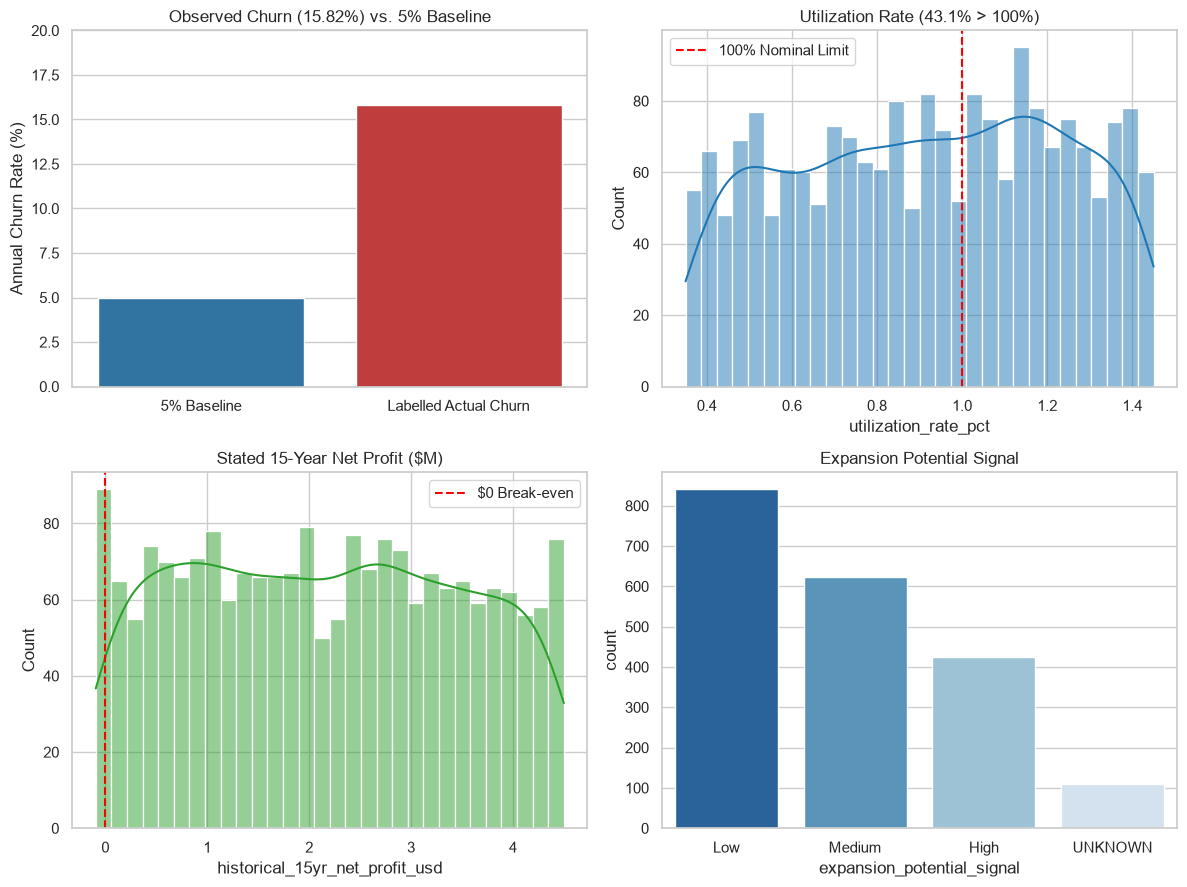

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Churn vs Baseline
sns.barplot(x=['5% Baseline', 'Labelled Actual Churn'], 
            y=[5.0, obs_churn_rate*100], 
            palette=['#1f77b4', '#d62728'], ax=axes[0, 0])
axes[0, 0].set_title("Observed Churn (15.82%) vs. 5% Baseline")
axes[0, 0].set_ylabel("Annual Churn Rate (%)")
axes[0, 0].set_ylim(0, 20)

# 2. Utilization Distribution
sns.histplot(df['utilization_rate_pct'], bins=30, kde=True, color='#1f77b4', ax=axes[0, 1])
axes[0, 1].axvline(1.0, color='red', linestyle='--', label='100% Nominal Limit')
axes[0, 1].set_title("Utilization Rate (43.1% > 100%)")
axes[0, 1].legend()

# 3. Profit Distribution
sns.histplot(df['historical_15yr_net_profit_usd'] / 1e6, bins=30, kde=True, color='#2ca02c', ax=axes[1, 0])
axes[1, 0].axvline(0, color='red', linestyle='--', label='$0 Break-even')
axes[1, 0].set_title("Stated 15-Year Net Profit ($M)")
axes[1, 0].legend()

# 4. Expansion Signal
sns.countplot(data=df, x='expansion_potential_signal', 
              order=['Low', 'Medium', 'High', 'UNKNOWN'], 
              palette='Blues_r', ax=axes[1, 1])
axes[1, 1].set_title("Expansion Potential Signal")

plt.tight_layout()
plt.show()

### 13. Data Cleaning & Transformation
We now apply our verified cleaning rules to produce `cleaned_data.csv`:
1. `is_label_known`: 1 if churn label is present, 0 if missing.
2. `utilization_capped`: min(utilization, 1.0).
3. `over_capacity`: 1 if utilization > 1.0, 0 otherwise.
4. `utilization_excess`: max(utilization - 1.0, 0.0).
5. `negative_profit_flag`: 1 if profit < 0, 0 otherwise.
6. `profit_signed_log`: sign(profit) * ln(1 + |profit|).

In [15]:
import sys
# Ensure project root is on sys.path
for p in [Path("..").resolve(), Path(".").resolve()]:
    if (p / "src").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

from src.cleaning import clean_dataset, generate_data_quality_report

# Apply verified cleaning rules
cleaned_df = clean_dataset(df)

# Generate and display data quality report
dq_report = generate_data_quality_report(df)
print("Data Quality Report Table:")
dq_report

Data Quality Report Table:


,column,dtype,missing_count,missing_pct,unique_count,min,max,mean,median
0,account_id,str,0,0.0,1000,,,,
1,array_id,str,0,0.0,2000,,,,
2,contract_end_date,str,0,0.0,1000,,,,
3,historical_15yr_net_profit_usd,int64,0,0.0,2000,-93780.0,4498824.0,2152844.782,2134327.5
4,current_capacity_tb,int64,0,0.0,1366,53.0,2498.0,1282.771,1305.5
5,utilization_rate_pct,float64,0,0.0,111,0.35,1.45,0.917,0.93
6,static_baseline_churn_rate,float64,0,0.0,1,0.05,0.05,0.05,0.05
7,churn_event_next_12m,float64,116,5.8,2,0.0,1.0,0.1582,0.0
8,expansion_potential_signal,str,0,0.0,4,,,,


### 14. Save Processed Dataset
We persist the cleaned dataset to `../data/processed/cleaned_data.csv`.

In [16]:
out_path = Path("../data/processed/cleaned_data.csv")
if not out_path.parent.parent.exists() and Path("data/processed").parent.exists():
    out_path = Path("data/processed/cleaned_data.csv")

out_path.parent.mkdir(parents=True, exist_ok=True)
cleaned_df.to_csv(out_path, index=False)

print(f"Cleaned dataset successfully saved to: {out_path.resolve()}")
print(f"Total rows: {len(cleaned_df)}, Total columns: {cleaned_df.shape[1]}")

Cleaned dataset successfully saved to: C:\Users\anura\.gemini\antigravity\scratch\CLV-Truth-Engine\data\processed\cleaned_data.csv
Total rows: 2000, Total columns: 15


### 15. Final Verification & Sanity Checks
Ensure all core invariants hold before concluding Phase 1.

In [17]:
assert len(cleaned_df) == 2000, "Cleaned dataset row count must be 2000"
assert cleaned_df['churn_event_next_12m'].isnull().sum() == 116, "116 missing labels must be preserved"
assert (cleaned_df['is_label_known'] == 1).sum() == 1884, "Exactly 1884 labelled rows"
assert (cleaned_df['negative_profit_flag'] == 1).sum() == 58, "58 negative profits must be flagged"
assert (cleaned_df['over_capacity'] == 1).sum() == 862, "862 over-capacity rows must be flagged"
assert (cleaned_df['account_id'].value_counts() == 2).all(), "Exactly 2 arrays per account"
assert cleaned_df['array_id'].nunique() == 2000, "Array IDs must be unique"

print("All Phase 1 audit and cleaning sanity checks PASSED.")

All Phase 1 audit and cleaning sanity checks PASSED.
